In [64]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm,poisson,rayleigh

#### 1A

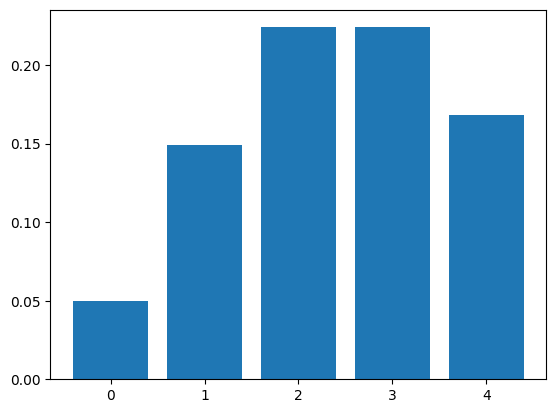

In [60]:
#1A
X=3
Y=5
#1 day
kr=np.arange(0,Y)
pois=poisson.pmf(kr,X)
plt.bar(kr,pois);

#### 1B

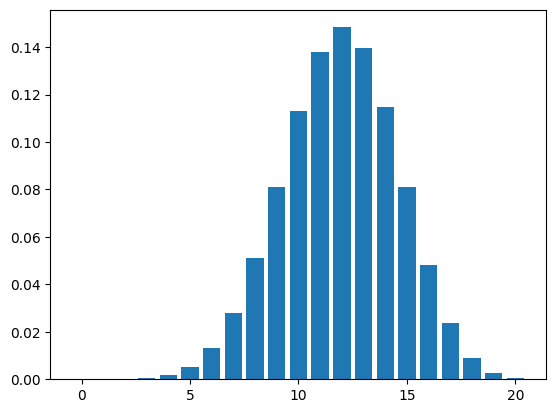

In [24]:
def ncv(n,pmf):
    result=pmf
    for i in range(n-1):
        result=np.convolve(result,pmf)
    return result/np.sum(result) #Normalization
def pltcv(n,pmf):
    cvn=ncv(n,pmf)
    plt.bar(np.arange(0,len(cvn)),cvn)
#5 days convolution
pltcv(5,pois)

#### 1C

We can see that the right tail is steeper than the left tail, but it is also closer to normal distribution.

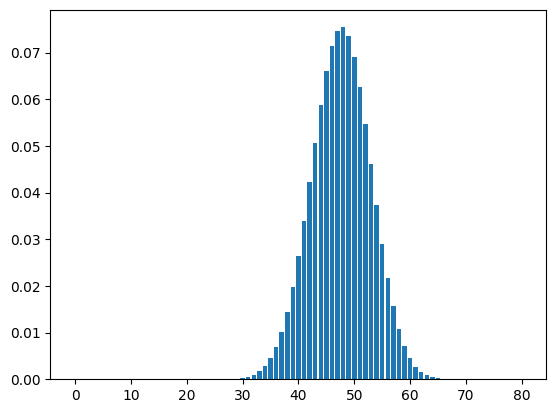

In [ ]:
#let's use n=20
pltcv(20,pois)

Now, the average of the Poissons looks like Gaussian, as stated in CLT that the distribution approches normal distribution regardless of the individual distributions.

#### 1D

In [ ]:
#I pick n=20
cv_20=ncv(20,pois)
kr_20=np.arange(0,len(cv_20))
mu_20=np.sum(cv_20*kr_20)
sig2_20=np.sum(cv_20*kr_20**2)-mu_20**2
print(f"The mean is {mu_20:.3f}, and the sigma is {sig2_20**(1/2):.3f}")

The mean is 47.634, and the sigma is 5.256


# Problem 2

#### 2A

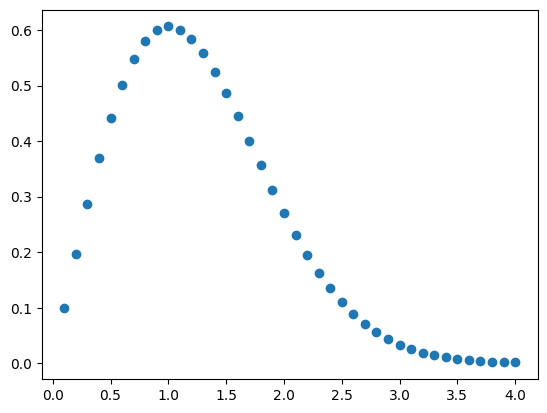

In [ ]:
#2A
xlist=np.linspace(0.1,4,40)
ray=rayleigh.pdf(x=xlist,scale=1)
plt.scatter(xlist,ray) #plt.bar has a glitch where the values near the peak are all the same (flat plateau)

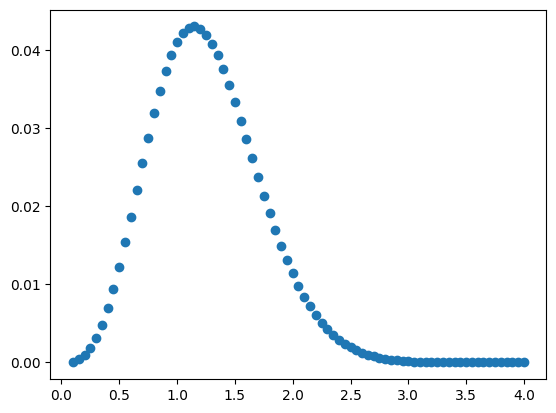

In [62]:
ray2=ncv(2,ray)
plt.scatter(np.linspace(0.1,4,2*(len(ray)-1)+1),ray2)

It starts to look less like Rayleigh and more like Gaussian

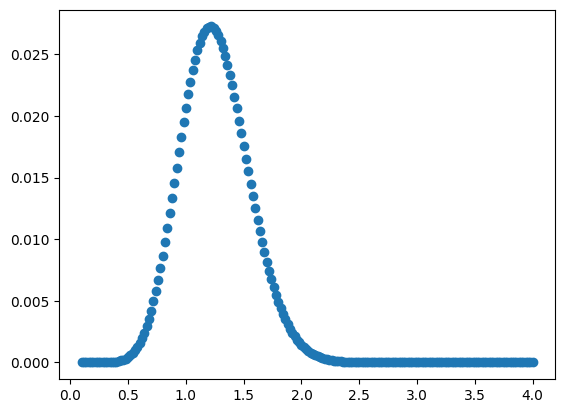

In [61]:
ray5=ncv(5,ray)
plt.scatter(np.linspace(0.1,4,5*(len(ray)-1)+1),ray5)

#### 2B
Now, it looks like Gaussian. It seems to approach Gaussian, as stated in CLT again.

# Problem 3

#### 3A
SNR is $\frac{y-\mu}{x}$

In [85]:
x=3.6
y=20.26
SNR=(y-0)/x
P1=norm.sf(SNR)
print(f"The detection has the significance of {SNR:.2f} sigmas with the p-value of {P1:.4e} ")

The detection has the significance of 5.63 sigmas with the p-value of 9.1273e-09 


So, it is good enough to proclaim a discovery

#### 3B
What is the p-value that 10000 background pixels would have at least 1 pixel brighter than Y? Let's call that $P_{10k}$ \
We should use the probability that background is not brighter than Y, then subtracts that from 1. \
$P(BG<y) = (1-P_1), P_N(BG<y) = (1-P_1)^N, P_{10k} = 1 - P_N(BG<y) = 1-(1-P_1)^{10000}$

#### 3C

In [83]:
P10k=1-(1-P1)**10000
print(f"The p-value of background being Y is {P10k:.3e}, corresponding to {norm.isf(P10k):.2f} sigmas")

The p-value of background being Y is 9.127e-05, corresponding to 3.74 sigmas


Now, it is not good enough for a discovery

# Problem 4
To get $5\sigma$, the SNR has to be 5.

#### 4A

In [ ]:
print(f"The y has to be {5*x}")

The Y has to be 18.0


#### 4B
To get $5\sigma$, $P_{10k}$ needs to be equal to the p-value of $5\sigma$ 

In [ ]:
P1px=(1-norm.sf(5))**(1/10000)
SNR10k=abs(norm.isf(P1px))
print(f"The y has to be {SNR10k*x:.3f} and {SNR10k:.3f} sigmas")

The y has to be 23.582 with 6.551 sigmas


#### 4C
The penalty is low (from 5 sigmas to 6.55 sigmas) is because the Gaussian tail becomes more steep, making 10000 fit within that difference.

#### 4D
The tail becomes steep, so even if the trials factor changed by orders of magnitude, it will not be lower than 5 (low N), and would increase not much (Since it increases 1.55 even if N is 10000)

#### Extra
If the distribution is non-Gaussian, the sensitivity would change. One example is Cauchy, which has fat tails, would make the 10000 change more than just 1.55 sigmas.